In [10]:
import open3d as o3d
import numpy as np
import copy
import sys

#load point cloud
print("load a ply point cloud, print it, and render it")
pcd = o3d.io.read_point_cloud(r"C:/Users/User/Desktop/open3D_tutorial/data/extract/DemoCropPointCloud/fragment.ply")
o3d.visualization.draw_geometries([pcd])

load a ply point cloud, print it, and render it


### ICP Registration
The input are **two point clouds** and an **initial transformation** that roughly aligns the **source point cloud** to the **target point cloud**. The output is a refined transformation that tightly aligns the two point clouds. A helper function `draw_registration_result` visualizes the alignment **during** the registration process. In this tutorial, we show two ICP variants, the point-to-point ICP and the point-to-plane ICP

该算法的输入包括**两个点云**以及一个**初始变换矩阵**，该矩阵用于将**源点云**与**目标点云**进行粗略对齐。
算法的输出是一个经过优化的变换矩阵，使两个点云能够更加精确地对齐。
辅助函数`draw_registration_result` 用于可视化配准过程中的点云对齐结果。
在本教程中，我们将介绍 ICP 算法的两种变体：
1. Point-to-Point ICP（点到点 ICP）
2. Point-to-Plane ICP（点到面 ICP）  
参考文献：[Rusinkiewicz2001]

### Helper visualization function 辅助可视化函数
The function `draw_registration_result` below visualizes a **target point cloud** and a **source point cloud transformed** with an alignment transformation. The target point cloud and the source point cloud are painted with cyan and yellow colors respectively. The more and tighter the two point clouds overlap with each other, the better the alignment result.

下面的函数`draw_registration_result`用于可视化**目标点云**以及经过**对齐变换后的源点云**。
- 目标点云：青色（Cyan）
- 变换后的源点云：黄色（Yellow）  
两个点云之间的重叠区域越大、重合程度越高，说明配准结果越好

In [11]:
#3个参数：源点云、目标点云、4*4变换阵
#变换阵通过ICP（可能也需要initial registration的变换阵）得到
def draw_registration_result(source, target, transformation):
    #创建源点云和目标点云的副本，因为后面要染色，直接在原始点云上改的话会修改原始数据
    #用pythond的copy.deepcopy复制，所以一开始要import copy
    source_temp = copy.deepcopy(source)
    target_temp = copy.deepcopy(target)
    #给点云设置颜色
    source_temp.paint_uniform_color([1, 0.706, 0])     #变换后的源点云黄色
    target_temp.paint_uniform_color([0, 0.651, 0.929]) #目标点云青色
    #将源点云副本变换到目标点云的坐标系Initial Registration
    #只变换源点云，不变换目标点云
    source_temp.transform(transformation)
    o3d.visualization.draw_geometries([source_temp, target_temp])

### Input 输入
The code below reads a source point cloud and a target point cloud from two files. A rough transformation is given.

下面的代码从两个文件中分别读取源点云和目标点云。同时，给定一个粗略的变换矩阵

### Note 注意
The initial alignment is usually obtained by a **global registration** or **marker detection** algorithm.

初始对齐通常通过**全局配准算法**或者**marker detection** 获得。

In [12]:
#读取源点云和目标点云
source = o3d.io.read_point_cloud(r"C:/Users/User/Desktop/open3D_tutorial/data/extract/DemoICPPointClouds/cloud_bin_0.pcd")
target = o3d.io.read_point_cloud(r"C:/Users/User/Desktop/open3D_tutorial/data/extract/DemoICPPointClouds/cloud_bin_1.pcd")
o3d.visualization.draw_geometries([source, target])

#设置距离阈值，在后续 ICP 配准中，这个阈值通常作为 Maximum Correspondence Distance
#若两个点的距离小于0.02，则可以作为correpondence的点
#threshold越小越严格
threshold = 0.02

#定义initial registration的变换矩阵。是一个4*4的变换阵，R,t,0,1
#可以从marker detection或者global registrtaion获得
trans_init = np.asarray([
     [0.862, 0.011, -0.507, 0.5],
     [-0.139, 0.967, -0.215, 0.7],
     [0.487, 0.255, 0.835, -1.4],
     [0.0, 0.0, 0.0, 1.0]
 ])

#调用上面自定义的函数，显示initial registration后的效果
draw_registration_result(source, target, trans_init)

### Evaluation
The function `evaluate_registration` calculates two main metrics:
- `fitness`, which measures the overlapping area (# of inlier correspondences / # of points in source). The higher the better.
- `inlier_rmse`, which measures the RMSE (Root Mean Square Error) of all inlier correspondences. The lower the better

函数 `evaluate_registration` 用于计算两个主要的评价指标：
- `fitness`（配准适应度）：用于衡量两个点云之间的重叠程度，其计算方式为：有效对应点对（Inlier Correspondences）的数量除以源点云（Source Point Cloud）中的点数。该值越高，表示配准效果越好。越接近1越好
- `inlier_rmse`（有效对应点的均方根误差）：用于衡量所有有效对应点对之间的均方根误差。该值越低，表示配准误差越小。

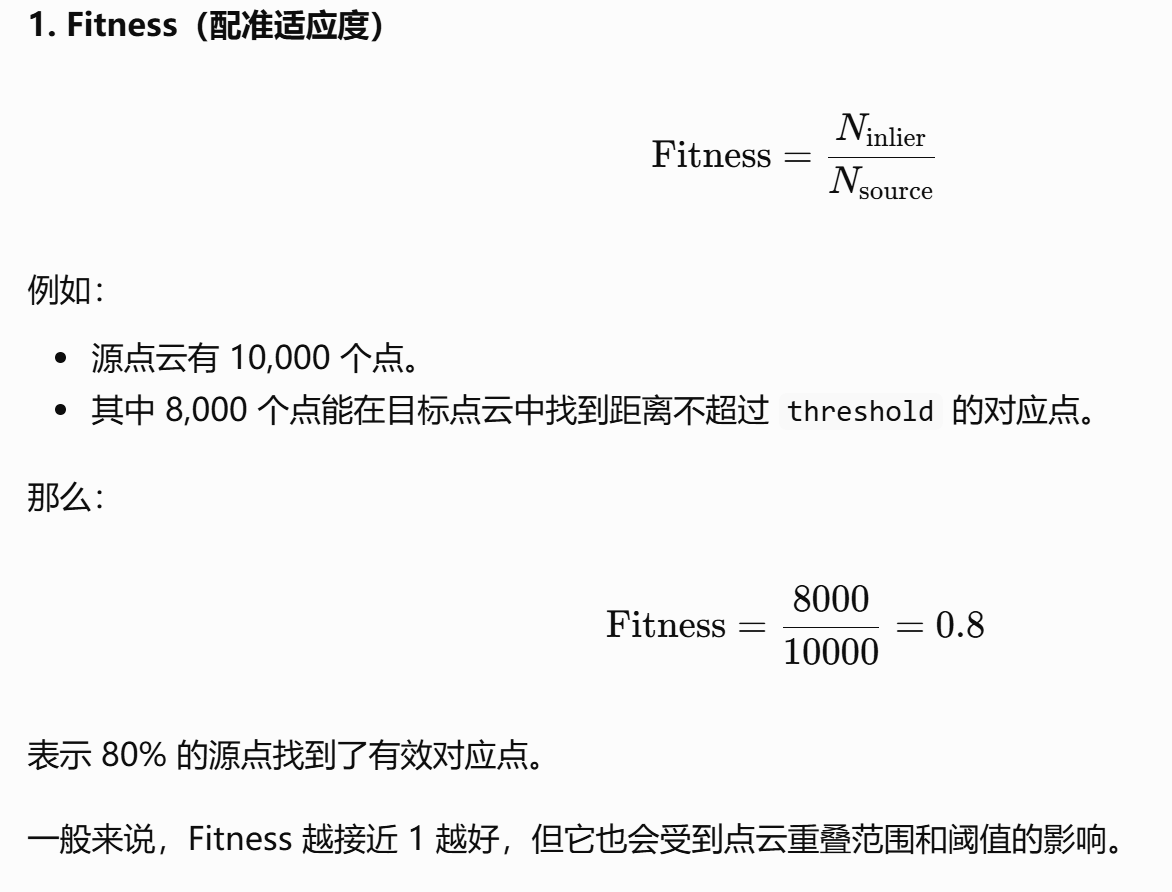
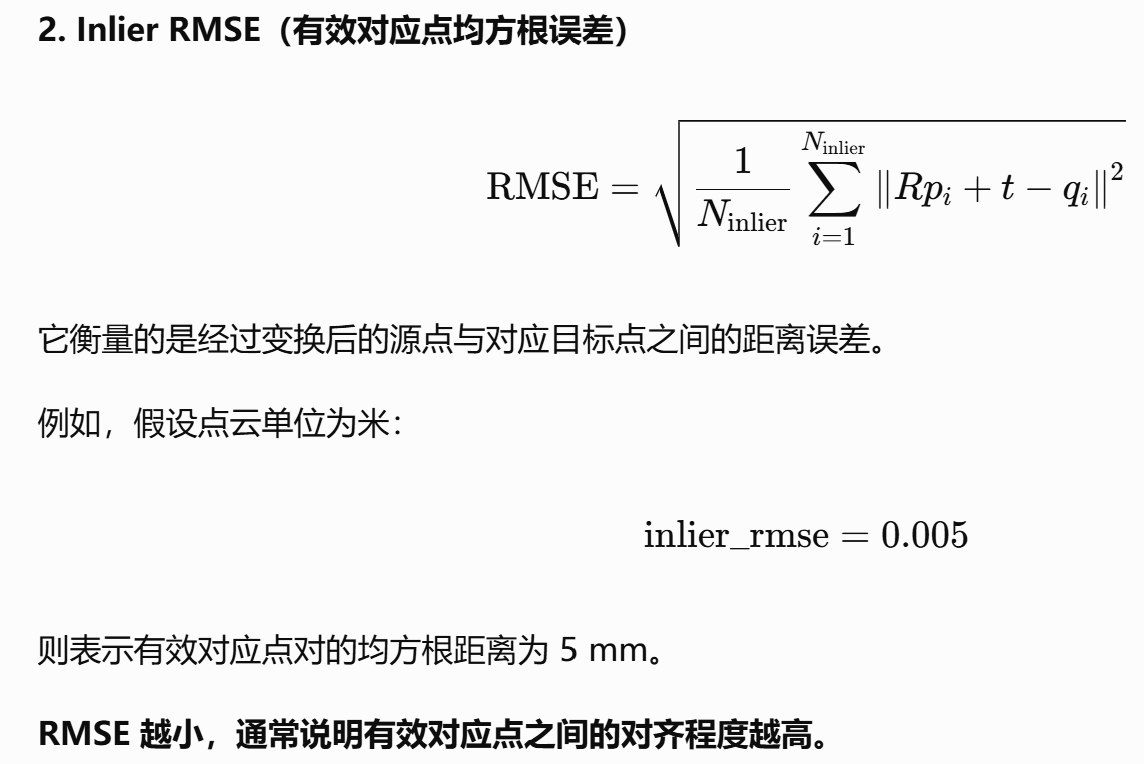

In [13]:
#初始配准效果Evaluation
print("Initial Alignment")
evaluation = o3d.pipelines.registration.evaluate_registration(
    source, target, threshold, trans_init
)
print(evaluation)

Initial Alignment
RegistrationResult with fitness=1.747228e-01, inlier_rmse=1.177106e-02, and correspondence_set size of 34741
Access transformation to get result.


### Point-to-point ICP 点到点ICP
In general, the ICP algorithm iterates over two steps:
1. Find correspondence set K={(p,q)} from target point cloud P, and source point cloud Q transformed with current transformation matrix T.
2. Update the transformation T by minimizing an objective function E(T) defined over the correspondence set K.  
Different variants of ICP use different objective functions E(T) [BeslAndMcKay1992] [ChenAndMedioni1992] [Park2017].  
We first show a point-to-point ICP algorithm [BeslAndMcKay1992] using the objective
$$
E(\mathbf{T}) = \sum_{(\mathbf{p},\mathbf{q})\in\mathcal{K}} \left\|\mathbf{p}-\mathbf{T}\mathbf{q}\right\|^2
$$
The class `TransformationEstimationPointToPoint` provides functions to compute the **residuals** and **Jacobian matrices** of the point-to-point ICP objective. The function `registration_icp` takes it as a parameter and runs point-to-point ICP to obtain the results.

通常情况下，ICP 算法会反复迭代执行以下两个步骤：
1. 寻找对应点集：从目标点云P和经过当前变换矩阵T变换后的源点云Q 中，寻找对应点对，构建对应点集K={(p,q)}。
2. 更新变换矩阵：通过最小化定义在对应点集K上的目标函数E(T)，对变换矩阵T进行优化更新。
$$
E(\mathbf{T}) = \sum_{(\mathbf{p},\mathbf{q})\in\mathcal{K}} \left\|\mathbf{p}-\mathbf{T}\mathbf{q}\right\|^2
$$ 
不同的 ICP 变体采用不同的目标函数E(T)[BeslAndMcKay1992] [ChenAndMedioni1992] [Park2017]。  
首先，我们介绍采用以下目标函数的点到点 ICP 算法（Point-to-point ICP） [BeslAndMcKay1992]

In [14]:
print("Apply point-to-point ICP")
#执行点到点ICP
#registratin_icp是open3D的点云配准函数
#不需要先生成一个粗配准后的点云，再把这个点云传入 ICP。 Open3D 会自动利用初始变换矩阵完成这一步。
#只需要粗配准的参数source,traget, threshold, trans_init和ICP配准的函数就行
reg_p2p = o3d.pipelines.registration.registration_icp(
    source, target, threshold, trans_init,  #到这里是执行initial registration
    o3d.pipelines.registration.TransformationEstimationPointToPoint(), #p2p ICP
    #设置最大的迭代次数，若不设置则默认30
    #迭代次数对配准效果也有影响，迭代次数越大，配准效果越好,但是计算时间也越长
    o3d.pipelines.registration.ICPConvergenceCriteria(max_iteration =2000) 
)
print(reg_p2p) #打印ICP配准结果，输出的是fitness, inlier_rmse以及correspondence_set size
#打印优化后的变换矩阵
print("Transdormation is:")
print(reg_p2p.transformation)

#用上面自定义的函数可视化
#reg_p2p.transformation是从原始源点云到目标点云的最终变换矩阵，而不是仅包含 ICP 优化增量的矩阵
draw_registration_result(source, target, reg_p2p.transformation) #

Apply point-to-point ICP
RegistrationResult with fitness=6.211230e-01, inlier_rmse=6.583448e-03, and correspondence_set size of 123501
Access transformation to get result.
Transdormation is:
[[ 0.84024592  0.00687676 -0.54241281  0.6463702 ]
 [-0.14819104  0.96517833 -0.21706206  0.81180074]
 [ 0.52111439  0.26195134  0.81189372 -1.48346821]
 [ 0.          0.          0.          1.        ]]


### Point-to-plane ICP 点到面ICP
The point-to-plane ICP algorithm [ChenAndMedioni1992] uses a different objective function 
$$
E(\mathbf{T}) = \sum_{(\mathbf{p},\mathbf{q})\in\mathcal{K}}
\left((\mathbf{p}-\mathbf{T}\mathbf{q})\cdot\mathbf{n}_p\right)^2
$$
where np is the normal of point p. [Rusinkiewicz2001] has shown that the point-to-plane ICP algorithm has a faster convergence speed than the point-to-point ICP algorithm.  
`registration_icp` is called with a different parameter `TransformationEstimationPointToPlane`.   
this class implements functions to compute the residuals and Jacobian matrices of the point-to-plane ICP objective.

点到面 ICP 算法 [ChenAndMedioni1992] 使用了与点到点 ICP 不同的目标函数（Objective Function）：  
$$
E(\mathbf{T}) = \sum_{(\mathbf{p},\mathbf{q})\in\mathcal{K}}
\left((\mathbf{p}-\mathbf{T}\mathbf{q})\cdot\mathbf{n}_p\right)^2
$$  
其中，np 表示目标点p处的法向量。[Rusinkiewicz2001] 的研究表明，与点到点 ICP 算法相比，点到面 ICP 算法具有更快的收敛速度。  
调用 `registration_icp` 函数时，需要使用不同的参数 `TransformationEstimationPointToPlane`。
该类实现了用于计算点到面 ICP 目标函数的**残差（Residuals）和雅可比矩阵（Jacobian Matrices）**的相关函数。

In [15]:
print("Apling point-to-plane ICP")
reg_p2l = o3d.pipelines.registration.registration_icp(
    source, target, threshold, trans_init,
    o3d.pipelines.registration.TransformationEstimationPointToPlane(),
    #默认迭代次数仍为30，30次迭代的结果已经和p2p2000次迭代的效果差不多了
    #o3d.pipelines.registration.ICPConvergenceCriteria(max_iteration=200)
)
print(reg_p2l)
#打印优化后的矩阵
print("Transformation is:")
print(reg_p2l.transformation)
draw_registration_result(source, target, reg_p2l.transformation)

Apling point-to-plane ICP
RegistrationResult with fitness=6.209722e-01, inlier_rmse=6.581453e-03, and correspondence_set size of 123471
Access transformation to get result.
Transformation is:
[[ 0.84023324  0.00618369 -0.54244126  0.64720943]
 [-0.14752342  0.96523919 -0.21724508  0.81018928]
 [ 0.52132423  0.26174429  0.81182576 -1.48366001]
 [ 0.          0.          0.          1.        ]]


特别注意：Point-to-Plane ICP 需要目标点云具有法向量信息（Normals）。  
不过使用 Point-to-Plane ICP 时，必须特别注意目标点云的法向量估计质量，这会直接影响精配准结果。  
如果你使用的是自己采集的点云，而且还没有计算法向量，可以先执行：（见01）

In [16]:
#计算点p的法向量时，Open3D会在点p周围寻找一批邻近点，然后根据这些邻近点估计出一个局部平面  
#垂直于这个局部平面的方向，就是点p的法向量  
#这里用的是hybrid混合邻域搜索，限制搜索半径radius为0.05，以及最大邻居点数max_nn为30  
#target.estimate_normals(  
#     search_param=o3d.geometry.KDTreeSearchParamHybrid(  
#         radius=0.05,  
#         max_nn=30  
#     )  
# )